In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

# Cargar el archivo CSV
archivo = files.upload()

# Leer los datos
datos = pd.read_csv("EN_Card_Data-selected-columns.csv")

# Mostrar las primeras filas
datos.head()


Saving EN_Card_Data-selected-columns.csv to EN_Card_Data-selected-columns.csv


,Card ID,Card Name,Expansion,Collection No.,Stage (Pokémon)/Type (Energy and Trainer),Rule,Category,Previous stage,HP,Type
0,1,Basic {G} Energy,SVE,1,Basic Energy,NaN,NaN,NaN,NaN,{G}
1,2,Basic {R} Energy,SVE,2,Basic Energy,NaN,NaN,NaN,NaN,{R}
2,3,Basic {W} Energy,SVE,3,Basic Energy,NaN,NaN,NaN,NaN,{W}
3,4,Basic {L} Energy,SVE,4,Basic Energy,NaN,NaN,NaN,NaN,{L}
4,5,Basic {P} Energy,SVE,5,Basic Energy,NaN,NaN,NaN,NaN,{P}


In [2]:

# Revisar el tamaño del dataset
print("Filas y columnas:", datos.shape)

# Revisar los nombres de las columnas
print("\nColumnas del dataset:")
print(datos.columns.tolist())

# Revisar los tipos de datos y valores faltantes
print("\nInformación general:")
datos.info()

# Revisar los valores faltantes
print("\nValores faltantes por columna:")
print(datos.isnull().sum())


Filas y columnas: (2022, 10)

Columnas del dataset:
['Card ID', 'Card Name', 'Expansion', 'Collection No.', 'Stage (Pokémon)/Type (Energy and Trainer)', 'Rule', 'Category', 'Previous stage', 'HP', 'Type']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2022 entries, 0 to 2021
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Card ID                                    2022 non-null   int64  
 1   Card Name                                  2022 non-null   object 
 2   Expansion                                  2012 non-null   object 
 3   Collection No.                             2022 non-null   int64  
 4   Stage (Pokémon)/Type (Energy and Trainer)  2022 non-null   object 
 5   Rule                                       353 non-null    object 
 6   Category                                   392 non-null    object 
 7   Previous stag

In [3]:

# Calcular la cantidad de valores faltantes
faltantes = datos.isnull().sum()

# Calcular el porcentaje de valores faltantes
porcentaje = (faltantes / len(datos)) * 100

# Crear una tabla de calidad de datos
calidad = pd.DataFrame({
    "Valores faltantes": faltantes,
    "Porcentaje (%)": porcentaje.round(2)
})

# Mostrar primero las columnas con más faltantes
calidad = calidad.sort_values(
    by="Porcentaje (%)",
    ascending=False
)

display(calidad)


,Valores faltantes,Porcentaje (%)
Rule,1669,82.54
Category,1630,80.61
Previous stage,1165,57.62
HP,207,10.24
Type,197,9.74
Expansion,10,0.49
Card Name,0,0.00
Card ID,0,0.00
Stage (Pokémon)/Type (Energy and Trainer),0,0.00
Collection No.,0,0.00


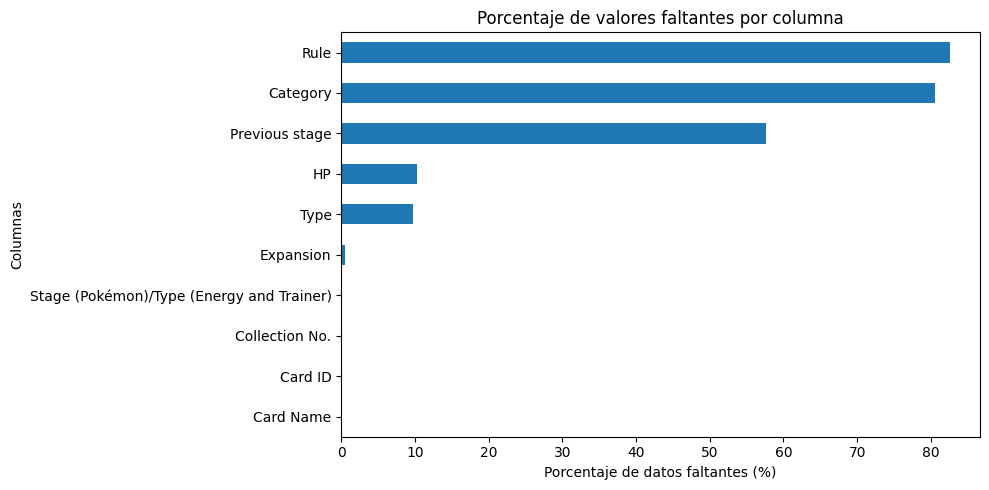

In [4]:

# Graficar el porcentaje de datos faltantes
plt.figure(figsize=(10, 5))

calidad["Porcentaje (%)"].sort_values().plot(
    kind="barh"
)

plt.title("Porcentaje de valores faltantes por columna")
plt.xlabel("Porcentaje de datos faltantes (%)")
plt.ylabel("Columnas")
plt.tight_layout()
plt.show()


In [5]:

# Revisar las categorías de cartas
print("Categorías:")
print(datos["Category"].value_counts(dropna=False))

print("\nTipos de carta o etapa:")
print(
    datos["Stage (Pokémon)/Type (Energy and Trainer)"]
    .value_counts(dropna=False)
)

print("\nTipos de Pokémon o cartas:")
print(datos["Type"].value_counts(dropna=False))

print("\nEjemplos de cartas sin HP:")
display(
    datos[datos["HP"].isnull()][
        ["Card Name", "Stage (Pokémon)/Type (Energy and Trainer)",
         "Category", "HP", "Type"]
    ].head(15)
)


Categorías:
Category
NaN                               1630
Trainer's Pokémon（Team Rocket）      85
Tera(Stellar)                       60
Ancient                             26
Trainer's Pokémon（N）                26
Trainer's Pokémon（Hop）              21
Future                              17
Trainer's Pokémon（Ethan）            15
Trainer's Pokémon（Larry）            13
Trainer's Pokémon（Steven）           12
Trainer's Pokémon（Marnie）           11
Trainer's Pokémon（Erika）            11
Trainer's Pokémon（Cynthia）          11
Trainer's Pokémon（Misty）            10
Fossil                              10
Trainer's Pokémon（Arven）            10
Tera(Lightning)                      9
Tera(Fighting)                       9
Trainer's Pokémon（Iono）              9
Trainer's Pokémon（Lillie）            7
Tera(Fire)                           6
Tera(Darkness)                       3
Tera(Water)                          3
Tera(Grass)                          3
Tera(Dragon)                         3
Tech

,Card Name,Stage (Pokémon)/Type (Energy and Trainer),Category,HP,Type
0,Basic {G} Energy,Basic Energy,NaN,NaN,{G}
1,Basic {R} Energy,Basic Energy,NaN,NaN,{R}
2,Basic {W} Energy,Basic Energy,NaN,NaN,{W}
3,Basic {L} Energy,Basic Energy,NaN,NaN,{L}
4,Basic {P} Energy,Basic Energy,NaN,NaN,{P}
5,Basic {F} Energy,Basic Energy,NaN,NaN,{F}
6,Basic {D} Energy,Basic Energy,NaN,NaN,{D}
7,Basic {M} Energy,Basic Energy,NaN,NaN,{M}
8,Boomerang Energy,Special Energy,NaN,NaN,{C}
9,Neo Upper Energy,Special Energy,NaN,NaN,{A}{A}


In [6]:

# Comparar el tipo de carta con los valores faltantes de HP

columnaEtapa = "Stage (Pokémon)/Type (Energy and Trainer)"

resumenHP = datos.groupby(
    columnaEtapa,
    dropna=False
).agg(
    Total_cartas=("Card ID", "count"),
    HP_faltante=("HP", lambda x: x.isnull().sum())
)

resumenHP["Porcentaje_HP_faltante"] = (
    resumenHP["HP_faltante"] /
    resumenHP["Total_cartas"] * 100
).round(2)

display(resumenHP)


,Total_cartas,HP_faltante,Porcentaje_HP_faltante
Stage (Pokémon)/Type (Energy and Trainer),,,
Basic Energy,8,8,100.0
Basic Pokémon,958,0,0.0
Item,82,72,87.8
Pokémon Tool,28,28,100.0
Special Energy,12,12,100.0
Stadium,26,26,100.0
Stage 1 Pokémon,618,0,0.0
Stage 2 Pokémon,229,0,0.0
Supporter,61,61,100.0


In [7]:

# Comparar las etapas con la información de Category

tablaCategoria = pd.crosstab(
    datos[columnaEtapa],
    datos["Category"].isnull(),
    margins=True
)

tablaCategoria.columns = [
    "Category informada",
    "Category faltante",
    "Total"
]

display(tablaCategoria)


,Category informada,Category faltante,Total
Stage (Pokémon)/Type (Energy and Trainer),,,
Basic Energy,0,8,8
Basic Pokémon,191,767,958
Item,12,70,82
Pokémon Tool,2,26,28
Special Energy,0,12,12
Stadium,0,26,26
Stage 1 Pokémon,136,482,618
Stage 2 Pokémon,49,180,229
Supporter,2,59,61


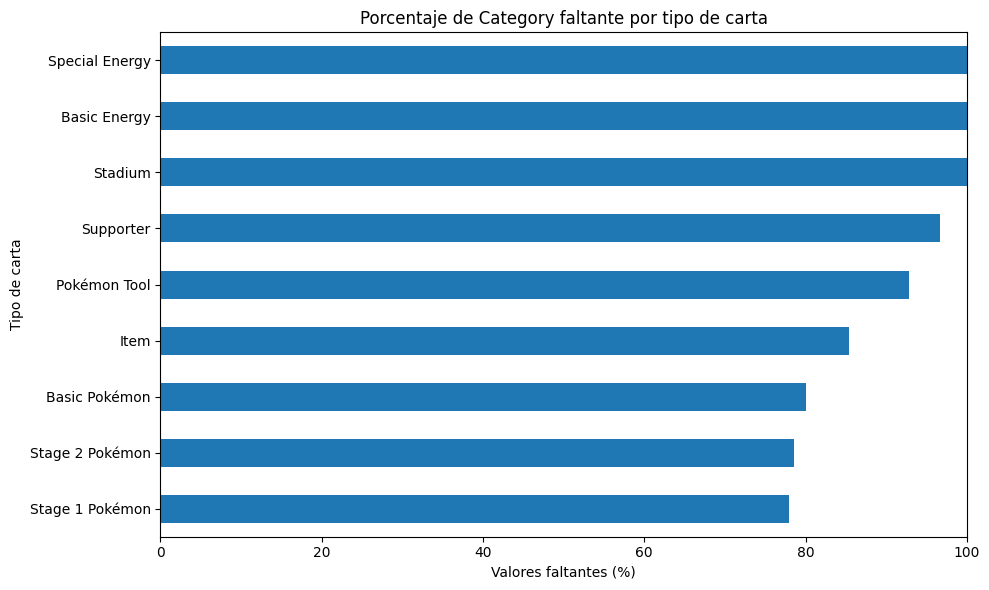

In [8]:

import matplotlib.pyplot as plt

# Calcular porcentaje de Category faltante por tipo de carta
faltantesCategoria = (
    datos.groupby(columnaEtapa)["Category"]
    .apply(lambda x: x.isnull().mean() * 100)
    .sort_values()
)

# Crear la gráfica
plt.figure(figsize=(10, 6))

faltantesCategoria.plot(kind="barh")

plt.title("Porcentaje de Category faltante por tipo de carta")
plt.xlabel("Valores faltantes (%)")
plt.ylabel("Tipo de carta")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


In [9]:

# Revisar identificadores duplicados
print(
    "Card ID duplicados:",
    datos["Card ID"].duplicated().sum()
)

# Revisar nombres repetidos
print(
    "Nombres de cartas repetidos:",
    datos["Card Name"].duplicated().sum()
)

# Mostrar ejemplos de nombres repetidos
nombresRepetidos = datos[
    datos["Card Name"].duplicated(keep=False)
].sort_values("Card Name")

display(nombresRepetidos.head(20))


Card ID duplicados: 755
Nombres de cartas repetidos: 926


,Card ID,Card Name,Expansion,Collection No.,Stage (Pokémon)/Type (Energy and Trainer),Rule,Category,Previous stage,HP,Type
751,419,Abomasnow,DRI,60,Stage 1 Pokémon,NaN,NaN,Snover,150.0,{W}
750,419,Abomasnow,DRI,60,Stage 1 Pokémon,NaN,NaN,Snover,150.0,{W}
1280,741,Abra,MEG,54,Basic Pokémon,NaN,NaN,NaN,50.0,{P}
189,109,Abra,TWM,80,Basic Pokémon,NaN,NaN,NaN,40.0,{P}
188,109,Abra,TWM,80,Basic Pokémon,NaN,NaN,NaN,40.0,{P}
1341,776,Absol,PFL,63,Basic Pokémon,NaN,NaN,NaN,110.0,{D}
1340,776,Absol,PFL,63,Basic Pokémon,NaN,NaN,NaN,110.0,{D}
1808,1067,Aegislash,POR,58,Stage 2 Pokémon,NaN,NaN,Doublade,150.0,{M}
1809,1067,Aegislash,POR,58,Stage 2 Pokémon,NaN,NaN,Doublade,150.0,{M}
456,245,Alakazam,TWM,82,Stage 2 Pokémon,NaN,NaN,Kadabra,140.0,{P}


In [10]:

# Revisar identificadores duplicados
print("Card ID duplicados:")
print(datos["Card ID"].duplicated().sum())

# Revisar filas completamente duplicadas
print("\nFilas completamente duplicadas:")
print(datos.duplicated().sum())

# Revisar duplicados considerando los datos de la carta
columnasCarta = [
    "Card Name",
    "Expansion",
    "Collection No.",
    "Stage (Pokémon)/Type (Energy and Trainer)",
    "Rule",
    "Category",
    "Previous stage",
    "HP",
    "Type"
]

print("\nCartas con características repetidas:")
print(datos.duplicated(subset=columnasCarta).sum())


Card ID duplicados:
755

Filas completamente duplicadas:
755

Cartas con características repetidas:
755


In [11]:
print(f"Tamaño original del dataset: {datos.shape}")

# Eliminar filas completamente duplicadas
datos_limpios = datos.drop_duplicates()

print(f"Nuevo tamaño tras eliminar duplicados: {datos_limpios.shape}")

# Verificar que ya no queden duplicados
duplicados_restantes = datos_limpios.duplicated().sum()
print(f"Duplicados restantes: {duplicados_restantes}")

Tamaño original del dataset: (2022, 10)
Nuevo tamaño tras eliminar duplicados: (1267, 10)
Duplicados restantes: 0


In [14]:
# Calcular la calidad de datos con el dataset limpio
faltantes_limpios = datos_limpios.isnull().sum()
porcentaje_limpios = (faltantes_limpios / len(datos_limpios)) * 100

calidad_limpia = pd.DataFrame({
    "Valores faltantes": faltantes_limpios,
    "Porcentaje (%)": porcentaje_limpios.round(2)
}).sort_values(by="Porcentaje (%)", ascending=False)

print("Nueva tabla de calidad de datos (sin duplicados):")
display(calidad_limpia)

Nueva tabla de calidad de datos (sin duplicados):


,Valores faltantes,Porcentaje (%)
Rule,1087,85.79
Category,1057,83.43
Previous stage,801,63.22
HP,206,16.26
Type,191,15.07
Expansion,8,0.63
Card Name,0,0.00
Card ID,0,0.00
Stage (Pokémon)/Type (Energy and Trainer),0,0.00
Collection No.,0,0.00


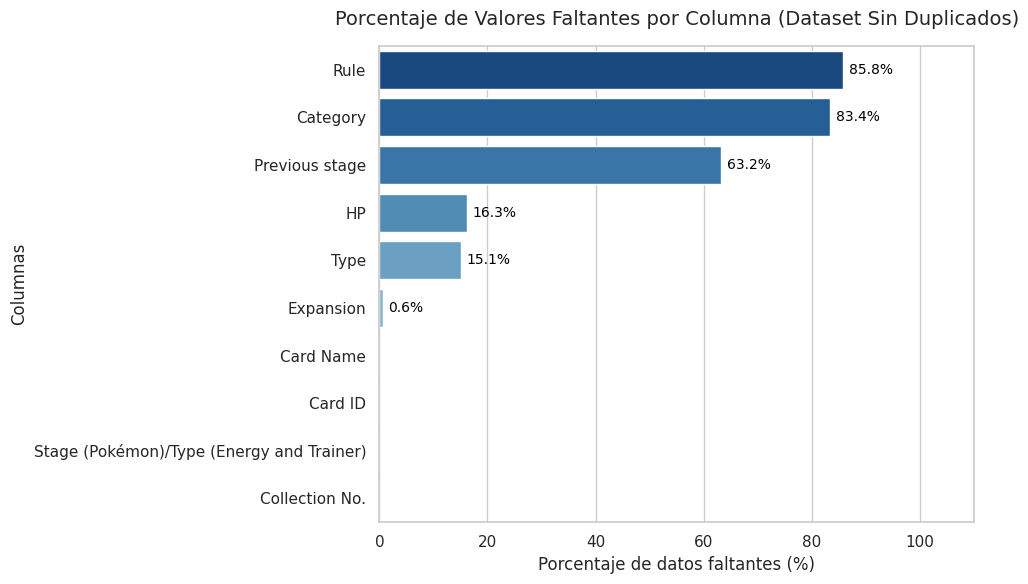

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configurar el estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear un gráfico de barras horizontales con seaborn para que sea más estético
ax = sns.barplot(
    x="Porcentaje (%)",
    y=calidad_limpia.index,
    data=calidad_limpia,
    palette="Blues_r",
    hue=calidad_limpia.index,
    legend=False
)

# Añadir las etiquetas de los porcentajes en cada barra
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(
            width + 1,
            p.get_y() + p.get_height() / 2,
            f"{width:.1f}%",
            ha="left",
            va="center",
            fontsize=10,
            color="black"
        )

plt.title("Porcentaje de Valores Faltantes por Columna (Dataset Sin Duplicados)", fontsize=14, pad=15)
plt.xlabel("Porcentaje de datos faltantes (%)", fontsize=12)
plt.ylabel("Columnas", fontsize=12)
plt.xlim(0, 110) # Margen para que quepan las etiquetas de texto
plt.tight_layout()
plt.show()

In [16]:
# Analizar valores faltantes de HP y Type cruzados con el tipo de carta en el dataset limpio
analisis_faltantes = datos_limpios.groupby('Stage (Pokémon)/Type (Energy and Trainer)', dropna=False).agg(
    Total_Cartas=('Card ID', 'count'),
    HP_Nulos=('HP', lambda x: x.isnull().sum()),
    Type_Nulos=('Type', lambda x: x.isnull().sum())
).reset_index()

display(analisis_faltantes)

,Stage (Pokémon)/Type (Energy and Trainer),Total_Cartas,HP_Nulos,Type_Nulos
0,Basic Energy,8,8,0
1,Basic Pokémon,595,0,0
2,Item,77,72,77
3,Pokémon Tool,27,27,27
4,Special Energy,12,12,0
5,Stadium,26,26,26
6,Stage 1 Pokémon,345,0,0
7,Stage 2 Pokémon,116,0,0
8,Supporter,61,61,61


In [17]:
# Crear una copia para evitar advertencias de asignación
datos_preparados = datos_limpios.copy()

# 1. Rellenar HP con 0 para cartas que no son Pokémon
es_pokemon = datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Pokémon', case=False)
datos_preparados.loc[~es_pokemon, 'HP'] = datos_preparados.loc[~es_pokemon, 'HP'].fillna(0)

# 2. Rellenar Type para cartas que no son Pokémon según su naturaleza
# Si es una carta de Energía (Basic o Special), le asignamos 'Energy'
es_energia = datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Energy', case=False)
datos_preparados.loc[es_energia, 'Type'] = datos_preparados.loc[es_energia, 'Type'].fillna('Energy')

# Para el resto de no-Pokémon (Items, Supporters, Stadium, Tools), les asignamos 'Trainer'
es_trainer = ~es_pokemon & ~es_energia
datos_preparados.loc[es_trainer, 'Type'] = datos_preparados.loc[es_trainer, 'Type'].fillna('Trainer')

# 3. Rellenar 'Previous stage' con 'None' para las cartas que no provienen de una etapa previa
datos_preparados['Previous stage'] = datos_preparados['Previous stage'].fillna('None')

# 4. Rellenar 'Rule' y 'Category' con 'None' si están vacíos
datos_preparados['Rule'] = datos_preparados['Rule'].fillna('None')
datos_preparados['Category'] = datos_preparados['Category'].fillna('None')

# Verificar el nuevo estado de valores faltantes
print("Valores faltantes restantes en el dataset preparado:")
print(datos_preparados.isnull().sum())

print("\nVista previa del dataset limpio y preparado:")
display(datos_preparados.head(10))

Valores faltantes restantes en el dataset preparado:
Card ID                                       0
Card Name                                     0
Expansion                                     8
Collection No.                                0
Stage (Pokémon)/Type (Energy and Trainer)     0
Rule                                          0
Category                                      0
Previous stage                                0
HP                                           27
Type                                         27
dtype: int64

Vista previa del dataset limpio y preparado:


,Card ID,Card Name,Expansion,Collection No.,Stage (Pokémon)/Type (Energy and Trainer),Rule,Category,Previous stage,HP,Type
0,1,Basic {G} Energy,SVE,1,Basic Energy,None,None,None,0.0,{G}
1,2,Basic {R} Energy,SVE,2,Basic Energy,None,None,None,0.0,{R}
2,3,Basic {W} Energy,SVE,3,Basic Energy,None,None,None,0.0,{W}
3,4,Basic {L} Energy,SVE,4,Basic Energy,None,None,None,0.0,{L}
4,5,Basic {P} Energy,SVE,5,Basic Energy,None,None,None,0.0,{P}
5,6,Basic {F} Energy,SVE,6,Basic Energy,None,None,None,0.0,{F}
6,7,Basic {D} Energy,SVE,7,Basic Energy,None,None,None,0.0,{D}
7,8,Basic {M} Energy,SVE,8,Basic Energy,None,None,None,0.0,{M}
8,9,Boomerang Energy,TWM,166,Special Energy,None,None,None,0.0,{C}
9,10,Neo Upper Energy,TEF,162,Special Energy,ACE SPEC,None,None,0.0,{A}{A}


In [18]:
# Filtrar e identificar las 27 cartas de Pokémon que aún tienen valores faltantes en HP o Type
pokemon_con_nulos = datos_preparados[
    datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Pokémon', case=False) &
    (datos_preparados['HP'].isnull() | datos_preparados['Type'].isnull())
]

print(f"Cantidad de cartas de Pokémon con valores nulos: {len(pokemon_con_nulos)}")
display(pokemon_con_nulos[['Card ID', 'Card Name', 'Stage (Pokémon)/Type (Energy and Trainer)', 'HP', 'Type']])

Cantidad de cartas de Pokémon con valores nulos: 27


,Card ID,Card Name,Stage (Pokémon)/Type (Energy and Trainer),HP,Type
1907,1154,Team Rocket’s Hypnotizer,Pokémon Tool,NaN,NaN
1908,1155,Survival Brace,Pokémon Tool,NaN,NaN
1909,1156,Lucky Helmet,Pokémon Tool,NaN,NaN
1910,1157,Rescue Board,Pokémon Tool,NaN,NaN
1911,1158,Maximum Belt,Pokémon Tool,NaN,NaN
1912,1159,Hero’s Cape,Pokémon Tool,NaN,NaN
1913,1160,Heavy Baton,Pokémon Tool,NaN,NaN
1914,1161,Handheld Fan,Pokémon Tool,NaN,NaN
1915,1162,Binding Mochi,Pokémon Tool,NaN,NaN
1916,1163,Powerglass,Pokémon Tool,NaN,NaN


In [20]:
# 1. Mostrar todos los tipos únicos de etapas para ver la clasificación exacta
print("Tipos de etapas únicos en el dataset:")
print(datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].unique())

# 2. Mostrar exactamente las 27 filas que aún tienen HP o Type nulo
filas_incompletas = datos_preparados[datos_preparados['HP'].isnull() | datos_preparados['Type'].isnull()]
print(f"\nFilas con valores nulos restantes: {len(filas_incompletas)}")
display(filas_incompletas[['Card ID', 'Card Name', 'Stage (Pokémon)/Type (Energy and Trainer)', 'HP', 'Type']].head(27))

Tipos de etapas únicos en el dataset:
['Basic Energy' 'Special Energy' 'Stage 1 Pokémon' 'Basic Pokémon'
 'Stage 2 Pokémon' 'Item' 'Pokémon Tool' 'Supporter' 'Stadium']

Filas con valores nulos restantes: 27


,Card ID,Card Name,Stage (Pokémon)/Type (Energy and Trainer),HP,Type
1907,1154,Team Rocket’s Hypnotizer,Pokémon Tool,NaN,NaN
1908,1155,Survival Brace,Pokémon Tool,NaN,NaN
1909,1156,Lucky Helmet,Pokémon Tool,NaN,NaN
1910,1157,Rescue Board,Pokémon Tool,NaN,NaN
1911,1158,Maximum Belt,Pokémon Tool,NaN,NaN
1912,1159,Hero’s Cape,Pokémon Tool,NaN,NaN
1913,1160,Heavy Baton,Pokémon Tool,NaN,NaN
1914,1161,Handheld Fan,Pokémon Tool,NaN,NaN
1915,1162,Binding Mochi,Pokémon Tool,NaN,NaN
1916,1163,Powerglass,Pokémon Tool,NaN,NaN


In [21]:
# 1. Crear de nuevo la copia limpia
datos_preparados = datos_limpios.copy()

# 2. Definir correctamente qué es un Pokémon real (que no sea un Pokémon Tool)
es_pokemon_real = (
    datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Pokémon', case=False) &
    ~datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Tool', case=False)
)

# 3. Rellenar HP con 0 para los no-Pokémon
datos_preparados.loc[~es_pokemon_real, 'HP'] = datos_preparados.loc[~es_pokemon_real, 'HP'].fillna(0)

# 4. Rellenar Type para las Energías
es_energia = datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Energy', case=False)
datos_preparados.loc[es_energia, 'Type'] = datos_preparados.loc[es_energia, 'Type'].fillna('Energy')

# 5. Rellenar Type para todo lo demás que no es Pokémon (Items, Tools, Supporters, Stadiums)
es_trainer_o_tool = ~es_pokemon_real & ~es_energia
datos_preparados.loc[es_trainer_o_tool, 'Type'] = datos_preparados.loc[es_trainer_o_tool, 'Type'].fillna('Trainer')

# 6. Rellenar otros campos de texto complementarios
datos_preparados['Previous stage'] = datos_preparados['Previous stage'].fillna('None')
datos_preparados['Rule'] = datos_preparados['Rule'].fillna('None')
datos_preparados['Category'] = datos_preparados['Category'].fillna('None')

# Verificar de nuevo los valores faltantes totales
print("Valores faltantes finales:")
print(datos_preparados.isnull().sum())

Valores faltantes finales:
Card ID                                      0
Card Name                                    0
Expansion                                    8
Collection No.                               0
Stage (Pokémon)/Type (Energy and Trainer)    0
Rule                                         0
Category                                     0
Previous stage                               0
HP                                           0
Type                                         0
dtype: int64


/tmp/ipykernel_2196/956927441.py:39: UserWarning: Glyph 31452 (\N{CJK UNIFIED IDEOGRAPH-7ADC}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 31452 (\N{CJK UNIFIED IDEOGRAPH-7ADC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


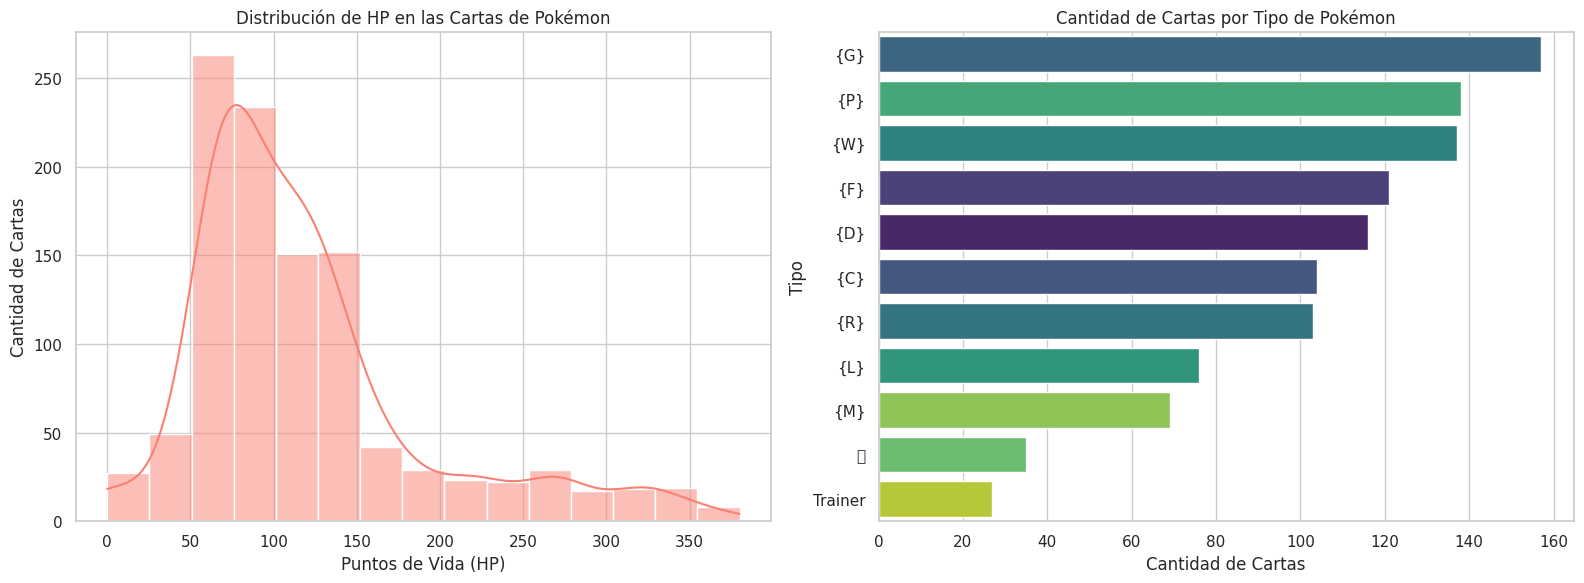

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filtrar únicamente los Pokémon reales para que el análisis de HP y Tipo sea correcto
pokemon_reales = datos_preparados[
    datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Pokémon', case=False)
]

# Crear una figura con 2 gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Distribución de HP para Pokémon
sns.histplot(
    data=pokemon_reales,
    x='HP',
    kde=True,
    ax=axes[0],
    color='salmon',
    bins=15
)
axes[0].set_title('Distribución de HP en las Cartas de Pokémon', fontsize=12)
axes[0].set_xlabel('Puntos de Vida (HP)')
axes[0].set_ylabel('Cantidad de Cartas')

# Gráfico 2: Frecuencia de Tipos de Pokémon
sns.countplot(
    data=pokemon_reales,
    y='Type',
    ax=axes[1],
    palette='viridis',
    order=pokemon_reales['Type'].value_counts().index,
    hue='Type',
    legend=False
)
axes[1].set_title('Cantidad de Cartas por Tipo de Pokémon', fontsize=12)
axes[1].set_xlabel('Cantidad de Cartas')
axes[1].set_ylabel('Tipo')

plt.tight_layout()
plt.show()

In [23]:
# 1. Crear un diccionario de mapeo para normalizar y unificar los tipos de Pokémon
mapeo_tipos = {
    '竜': 'Dragon',          # Corregir el carácter japonés que causaba error de fuente
    '{A}': 'Special/Astral',
    '{A}{A}': 'Special/Astral',
    '{C}{C}{C}': '{C}',      # Simplificar acumulaciones de energía incolora
    '{Team Rocket}{Team Rocket}': 'Team Rocket'
}

# Aplicar el reemplazo en el dataset preparado y en el filtro de pokémon reales
datos_preparados['Type'] = datos_preparados['Type'].replace(mapeo_tipos)

# Volver a filtrar los Pokémon reales con los tipos ya normalizados
pokemon_reales = datos_preparados[
    datos_preparados['Stage (Pokémon)/Type (Energy and Trainer)'].str.contains('Pokémon', case=False)
]

# Verificar los tipos únicos resultantes para asegurar que todo esté limpio
print("Tipos de Pokémon únicos normalizados:")
print(pokemon_reales['Type'].unique())

Tipos de Pokémon únicos normalizados:
['{D}' '{F}' '{C}' '{G}' '{R}' '{W}' '{L}' '{P}' 'Dragon' '{M}' 'Trainer']


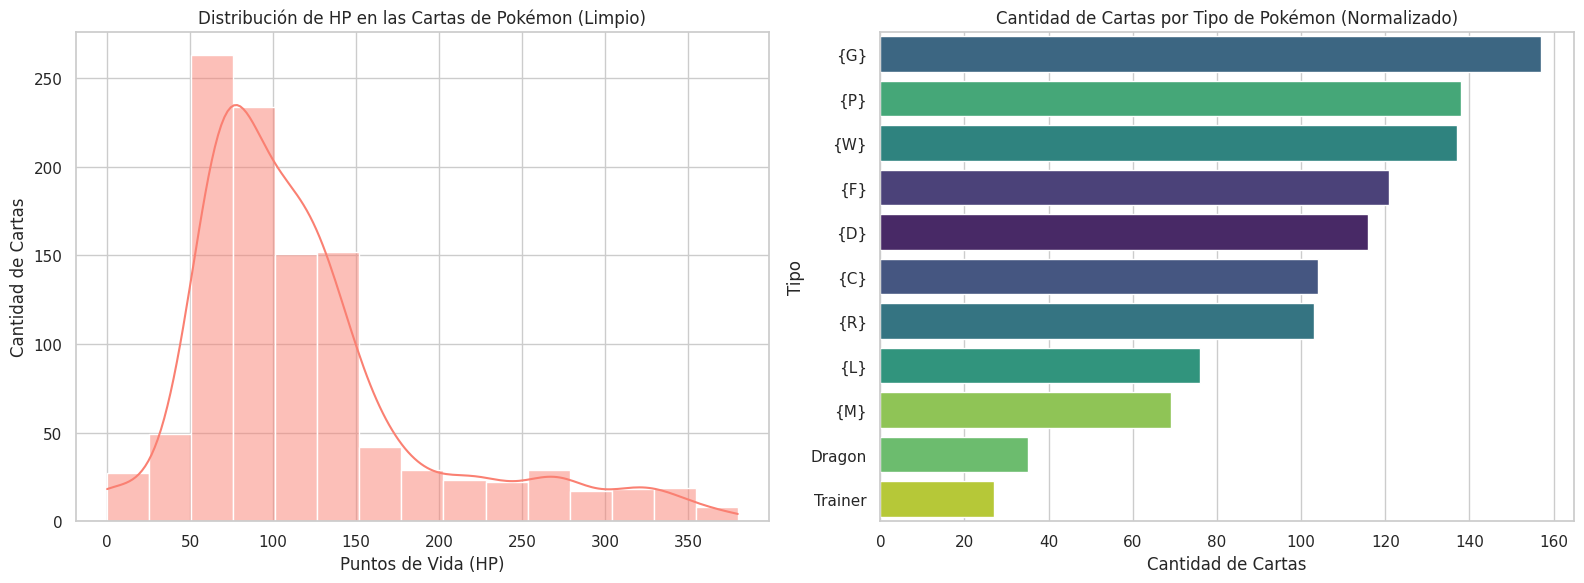

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Crear una figura con 2 gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Distribución de HP para Pokémon
sns.histplot(
    data=pokemon_reales,
    x='HP',
    kde=True,
    ax=axes[0],
    color='salmon',
    bins=15
)
axes[0].set_title('Distribución de HP en las Cartas de Pokémon (Limpio)', fontsize=12)
axes[0].set_xlabel('Puntos de Vida (HP)')
axes[0].set_ylabel('Cantidad de Cartas')

# Gráfico 2: Frecuencia de Tipos de Pokémon normalizados
sns.countplot(
    data=pokemon_reales,
    y='Type',
    ax=axes[1],
    palette='viridis',
    order=pokemon_reales['Type'].value_counts().index,
    hue='Type',
    legend=False
)
axes[1].set_title('Cantidad de Cartas por Tipo de Pokémon (Normalizado)', fontsize=12)
axes[1].set_xlabel('Cantidad de Cartas')
axes[1].set_ylabel('Tipo')

plt.tight_layout()
plt.show()

In [25]:
# Guardar el dataset limpio y preparado a un archivo CSV
nombre_archivo_limpio = 'EN_Card_Data-cleaned.csv'
datos_preparados.to_csv(nombre_archivo_limpio, index=False)

print(f"¡Dataset guardado con éxito como '{nombre_archivo_limpio}'!")

# Permitir la descarga directa en el navegador
from google.colab import files
files.download(nombre_archivo_limpio)
#ayuda a volverlo a usar ya limpio :)


¡Dataset guardado con éxito como 'EN_Card_Data-cleaned.csv'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Al comenzar con el dataset original, nos encontramos con un volumen de información redundante importante, del cual logramos filtrar y remover 755 filas que estaban completamente duplicadas. Una vez que nos quedamos con las 1,267 cartas únicas, el verdadero reto fue organizar las columnas de puntos de vida (HP) y tipos, ya que tenían bastantes vacíos. En lugar de borrar registros valiosos, decidimos darle una lógica según la naturaleza de cada carta: a las cartas que no representan Pokémon en juego (como las Energías, los Estadios y los Objetos de Entrenador) les asignamos un valor de cero en HP para mantener la consistencia numérica.

Durante este proceso detectamos que las cartas catalogadas como "Pokémon Tool" se nos estaban mezclando con los Pokémon reales debido a la palabra clave, lo que dejaba algunos valores nulos flotando por ahí; al ajustar la lógica y tratarlas correctamente como herramientas de Entrenador, logramos solucionar el problema por completo. Finalmente, unificamos las clasificaciones de tipo corrigiendo algunos textos extraños, como el símbolo japonés de los dragones que provocaba errores al graficar, simplificando también los códigos repetidos para que las visualizaciones de distribución de HP y popularidad de elementos quedaran impecables. Con esto, tu base de datos quedó completamente pulida, estructurada y lista para que la uses en cualquier análisis futuro.

